# LAB 4 — BƯỚC 1 (PHẦN A): TEXT NORMALIZATION & INVENTORY

**Học phần:** CSE457 — Xử lý âm thanh và tiếng nói  
**Mục tiêu:** Hoàn thiện mục **4.1 A** của tài liệu *Lab 4 — Tổng hợp tiếng nói*.

**Đầu ra phần A:**
1. `normalize_text()` chuyển câu miền hẹp thành danh sách token, đọc từng chữ số.
2. `lab4_data/units/` có ít nhất 15 word-unit (bài này dùng 16), mỗi unit có **2 bản ghi** khi hoàn tất.
3. Từng WAV chuẩn `16 kHz`, `mono`, `PCM_16`; mức RMS được điều chỉnh có kiểm soát.
4. `lab4_data/metadata.csv` gồm label, speaker, duration, RMS, file path.
5. Biểu đồ `figures/hist_duration.png` và `figures/hist_rms.png`.

**Lưu ý:** Notebook **không tự tạo giọng nói giả**. Bạn cần thu âm hoặc chép các file WAV thật vào `lab4_data/recordings_raw/`. Các cell phân tích có thể chạy khi chưa có dữ liệu, sẽ báo thiếu bản ghi.

## 0. Chuẩn bị môi trường

Chạy lệnh bên dưới trong **Terminal của VS Code**, tại thư mục đặt notebook:

```powershell
python -m pip install -r requirements_lab04_buoc1.txt
```

Trong VS Code mở `Lab04_Buoc1_A.ipynb` → **Select Kernel** → chọn Python đã cài thư viện. Trước khi thu âm, bảo đảm Windows cấp quyền microphone cho ứng dụng desktop.

In [1]:
from pathlib import Path
import sys
import re
import unicodedata
from math import gcd

import numpy as np
import pandas as pd
import soundfile as sf
import matplotlib.pyplot as plt
from scipy.signal import resample_poly
import librosa

ROOT = Path.cwd()  # mở VS Code ở folder dự án chứa notebook
DATA_DIR = ROOT / "lab4_data"
RAW_DIR = DATA_DIR / "recordings_raw"
UNIT_DIR = DATA_DIR / "units"
FIG_DIR = ROOT / "figures"
for folder in (DATA_DIR, RAW_DIR, UNIT_DIR, FIG_DIR):
    folder.mkdir(parents=True, exist_ok=True)

SR = 16000
TARGET_RMS = 0.08       # Mức tham chiếu theo ví dụ Lab 4; tránh tăng gain quá lớn
MAX_GAIN = 2.5
SPEAKER_ID = "spk01"    # 1 người đọc nhất quán sẽ giảm khác biệt giữa các unit

print("Python:", sys.version.split()[0])
print("Thư mục dự án:", ROOT)
print("Raw recordings:", RAW_DIR)
print("Processed units:", UNIT_DIR)


Python: 3.10.5
Thư mục dự án: c:\xulyamthanh\lab04_2351260688_NguyenNgocTien
Raw recordings: c:\xulyamthanh\lab04_2351260688_NguyenNgocTien\lab4_data\recordings_raw
Processed units: c:\xulyamthanh\lab04_2351260688_NguyenNgocTien\lab4_data\units


## 1. Định nghĩa 16 đơn vị và hai candidate cho mỗi unit

Case study trong PDF có các từ: *mời, khách, hàng, số, không–chín, đến, quầy* → **16 từ**. Tên file không dấu, nhưng `label` trong metadata **có dấu tiếng Việt**.

**Quy tắc:** cùng microphone, cùng khoảng cách; thu từng từ rõ dấu, để khoảng 100–200 ms khoảng lặng trước/sau lúc đọc, bước xử lý sẽ cắt về biên hợp lý.

In [2]:
UNIT_NAMES = {
    "mời": "moi", "khách": "khach", "hàng": "hang", "số": "so",
    "không": "khong", "một": "mot", "hai": "hai", "ba": "ba",
    "bốn": "bon", "năm": "nam", "sáu": "sau", "bảy": "bay",
    "tám": "tam", "chín": "chin", "đến": "den", "quầy": "quay",
}
DIGIT = {"0":"không", "1":"một", "2":"hai", "3":"ba", "4":"bốn",
         "5":"năm", "6":"sáu", "7":"bảy", "8":"tám", "9":"chín"}
N_CANDIDATES = 2

# Nếu bạn dùng dataset công khai, dùng tên người nói thật thay vì spk01.
source_provenance = DATA_DIR / "source_provenance.csv"
speaker_by_file = {}
if source_provenance.exists():
    provenance_df = pd.read_csv(source_provenance, encoding="utf-8-sig")
    speaker_by_file = dict(zip(provenance_df.filename, provenance_df.speaker))

expected = []
for label, slug in UNIT_NAMES.items():
    for take in range(1, N_CANDIDATES + 1):
        expected.append({
            "label": label,
            "speaker": speaker_by_file.get(f"{slug}_{take:02d}.wav", SPEAKER_ID),
            "take": take,
            "filename": f"{slug}_{take:02d}.wav",
        })
manifest = pd.DataFrame(expected)
manifest.to_csv(DATA_DIR / "inventory_manifest.csv", index=False, encoding="utf-8-sig")
print(f"Số từ: {len(UNIT_NAMES)}; tổng bản ghi mong đợi: {len(manifest)}")
display(manifest)


Số từ: 16; tổng bản ghi mong đợi: 32


,label,speaker,take,filename
0,mời,lephuong,1,moi_01.wav
1,mời,longtran,2,moi_02.wav
2,khách,lephuong,1,khach_01.wav
3,khách,longtran,2,khach_02.wav
4,hàng,lephuong,1,hang_01.wav
5,hàng,longtran,2,hang_02.wav
6,số,lephuong,1,so_01.wav
7,số,longtran,2,so_02.wav
8,không,lephuong,1,khong_01.wav
9,không,longtran,2,khong_02.wav


## 2. Xây dựng `normalize_text()`

**Quy tắc miền hẹp trong Lab:** chữ thường; loại dấu câu; tách từ; mỗi chữ số 0–9 đọc riêng (ví dụ `23` → `hai`, `ba`). Kiểm tra từ ngoài inventory, tránh tổng hợp sai im lặng.

**Lưu ý ngữ nghĩa:** đây là chuẩn hóa theo **mã số xếp hàng**, không phải quy tắc đọc số đếm tiếng Việt nói chung.

In [3]:
def normalize_text(text: str) -> list[str]:
    if not isinstance(text, str):
        raise TypeError("text phải là chuỗi str")
    text = unicodedata.normalize("NFC", text).lower().replace("_", " ")
    # Giữ chữ/số unicode, chuyển dấu câu thành khoảng trắng.
    text = re.sub(r"[^\w\s]", " ", text, flags=re.UNICODE)
    tokens = text.split()
    words = []
    for token in tokens:
        if token.isdecimal():
            # Bài lab sử dụng chữ số ASCII 0-9.
            if any(ch not in DIGIT for ch in token):
                raise ValueError(f"Chữ số ngoài 0–9 không được hỗ trợ: {token!r}")
            words.extend(DIGIT[ch] for ch in token)
        else:
            words.append(token)
    return words


def check_inventory_coverage(tokens: list[str]) -> None:
    unknown = sorted(set(tokens) - set(UNIT_NAMES))
    if unknown:
        raise ValueError("Các từ chưa có WAV trong inventory: " + ", ".join(unknown))

TEST_TEXT = "Mời khách hàng số 23 đến quầy 5."
expected_tokens = ["mời", "khách", "hàng", "số", "hai", "ba", "đến", "quầy", "năm"]
tokens = normalize_text(TEST_TEXT)
assert tokens == expected_tokens, (tokens, expected_tokens)
assert normalize_text("SỐ 007, quầy 2!") == ["số", "không", "không", "bảy", "quầy", "hai"]
check_inventory_coverage(tokens)
print("Câu gốc :", TEST_TEXT)
print("Token    :", tokens)
print("✓ Các kiểm thử text normalization đã qua")


Câu gốc : Mời khách hàng số 23 đến quầy 5.
Token    : ['mời', 'khách', 'hàng', 'số', 'hai', 'ba', 'đến', 'quầy', 'năm']
✓ Các kiểm thử text normalization đã qua


## 3. Thu âm WAV thực tế (có thể bỏ qua nếu bạn đã có WAV)

**Phương án A — Thu bằng microphone:** Chạy cell dưới đây để chọn từng từ; bấm Enter để thu, `s` để bỏ qua, `q` để dừng. Notebook thu bằng sample rate mặc định của micro rồi chuyển về WAV raw, xử lý 16 kHz ở bước sau. Ghi **2 lần khác nhau** cho mỗi từ.

**Phương án B — Bạn đã có dữ liệu:** chép các file WAV đúng tên trong `inventory_manifest.csv` vào `lab4_data/recordings_raw/`; không cần chạy cell thu âm.

> Để tránh thu nhầm hoặc ghi đè, các file đã tồn tại được mặc định bỏ qua.
**Phương án C — Dataset từ GitHub:** Chạy `python download_lab04_words.py` tại terminal trước khi xử lý WAV. Script lấy đúng các word-unit (nếu repo công khai cung cấp đường dẫn khớp), ghi `source_provenance.csv` và `recordings_raw/`. Nội dung của từng file phải được nghe kiểm tra trước khi coi là đúng nhãn.


In [4]:
def record_one(label: str, take: int, seconds: float = 2.5, speaker: str = SPEAKER_ID):
    """Thu một bản ghi từ microphone mặc định; sd chỉ cần cài nếu dùng chức năng này."""
    import sounddevice as sd
    if label not in UNIT_NAMES:
        raise ValueError("Từ không thuộc inventory: " + label)
    if take < 1:
        raise ValueError("take phải >= 1")
    name = f"{UNIT_NAMES[label]}_{take:02d}.wav"
    destination = RAW_DIR / name
    if destination.exists():
        raise FileExistsError(f"Đã tồn tại: {destination}. Hãy đổi tên/xóa thủ công nếu cần thu lại.")
    device = sd.query_devices(kind="input")
    input_sr = int(round(device["default_samplerate"]))
    if input_sr <= 0:
        raise RuntimeError("Không xác định được sample rate microphone")
    print(f"Đang thu '{label}' (lần {take}) trong {seconds}s, mic @ {input_sr} Hz ...")
    recording = sd.rec(int(round(seconds * input_sr)), samplerate=input_sr,
                       channels=1, dtype="float32")
    sd.wait()
    x = recording[:, 0]
    if np.max(np.abs(x)) < 1e-4:
        print("⚠ Tín hiệu gần như im lặng. Kiểm tra microphone trước khi tiếp tục.")
    sf.write(destination, x, input_sr, subtype="PCM_16")
    print("Đã lưu:", destination.name, "| speaker:", speaker)
    return destination


def record_missing_units(seconds: float = 2.5):
    print("Nhấn ENTER để bắt đầu từng bản ghi, 's' để bỏ qua, 'q' để dừng.")
    for item in expected:
        path = RAW_DIR / item["filename"]
        if path.exists():
            print("✓ Đã có:", path.name)
            continue
        cmd = input(f"Đọc '{item['label']}' — {path.name} [ENTER / s / q]: ").strip().lower()
        if cmd == "q":
            print("Đã dừng thu, có thể chạy lại khi muốn tiếp tục.")
            return
        if cmd == "s":
            continue
        try:
            record_one(item["label"], item["take"], seconds=seconds)
        except Exception as exc:
            print("Không thu được:", exc)
            print("Có thể dùng phương án B (chép WAV vào recordings_raw).")
            return

# BỎ DẤU # để THỰC SỰ bắt đầu ghi âm 32 bản:
# record_missing_units(seconds=2.5)


## 4. Chuẩn hóa WAV: mono, 16 kHz, trim silence, RMS

Mỗi WAV raw sẽ được đọc và lưu thành `lab4_data/units/<tên>.wav`, format **mono / 16 kHz / PCM_16**. Không chỉnh sửa bản thu gốc.

Cách xử lý trong notebook:
- Stereo → mono bằng trung bình hai kênh.
- Resample bằng `scipy.signal.resample_poly` (nếu cần).
- Cắt vùng im lặng quá dài với `librosa.effects.trim`; giữ đệm khoảng **30 ms** trước/sau để tránh xén âm.
- Điều chỉnh RMS về mức tham chiếu `0.08` nhưng giới hạn gain `2.5×` và tránh clipping. Nếu đoạn quá nhỏ, hãy **thu lại** thay vì ép gain lớn.

Trường hợp raw bị clip hoặc thiếu âm tiết, xử lý số không thể phục hồi chất lượng tốt.

In [5]:
def calc_rms(x: np.ndarray) -> float:
    x = np.asarray(x, dtype=np.float64)
    return float(np.sqrt(np.mean(x * x) + 1e-12)) if len(x) else 0.0


def resample_to_16k(y: np.ndarray, original_sr: int) -> np.ndarray:
    if original_sr == SR:
        return y.astype(np.float32)
    g = gcd(int(original_sr), SR)
    return resample_poly(y, SR // g, int(original_sr) // g).astype(np.float32)


def trim_with_padding(y: np.ndarray, pad_ms: float = 30.0) -> np.ndarray:
    if len(y) < 512:
        return y
    _, idx = librosa.effects.trim(y, top_db=35, frame_length=512, hop_length=128)
    padding = int(SR * pad_ms / 1000)
    start = max(0, int(idx[0]) - padding)
    end = min(len(y), int(idx[1]) + padding)
    return y[start:end]


def standardize_audio(source: Path, destination: Path):
    info = sf.info(source)
    x, fs = sf.read(source, dtype="float32", always_2d=True)
    mono = x.mean(axis=1)  # mono nếu nhiều kênh
    mono = resample_to_16k(mono, fs)
    if len(mono) < int(0.1 * SR):
        raise ValueError(f"Quá ngắn: {source.name}")
    trimmed = trim_with_padding(mono)
    if not len(trimmed):
        raise ValueError(f"WAV không có tín hiệu: {source.name}")
    raw_rms = calc_rms(trimmed)
    raw_peak = float(np.max(np.abs(trimmed)))
    if raw_peak < 1e-4:
        raise ValueError(f"Gần như im lặng: {source.name}")
    gain = min(MAX_GAIN, TARGET_RMS / max(raw_rms, 1e-9))
    # Giảm gain nếu đỉnh sẽ bị clipping, không cắt waveform cứng.
    gain = min(gain, 0.98 / raw_peak)
    output = (trimmed * gain).astype(np.float32)
    destination.parent.mkdir(parents=True, exist_ok=True)
    sf.write(destination, output, SR, subtype="PCM_16")
    return {
        "source_sr": int(fs), "source_channels": int(info.channels),
        "raw_rms": raw_rms,
        "duration": len(output) / SR,
        "rms": calc_rms(output),
        "peak": float(np.max(np.abs(output))),
        "gain": float(gain),
        "low_level_warning": bool(raw_rms < 0.01),
        "possible_clipping_warning": bool(raw_peak >= 0.995),
    }

# Lấy speaker ID thật từ dataset nguồn, nếu có, thay vì mặc định spk01.
provenance_path = DATA_DIR / "source_provenance.csv"
provenance_map = {}
if provenance_path.exists():
    source_table = pd.read_csv(provenance_path, encoding="utf-8-sig")
    provenance_map = dict(zip(source_table["filename"], source_table["speaker"]))
    print(f"Đã đọc thông tin người nói: {len(provenance_map)} bản ghi")

rows, errors = [], []
for item in expected:
    source = RAW_DIR / item["filename"]
    target = UNIT_DIR / item["filename"]
    if not source.exists():
        continue
    try:
        stats = standardize_audio(source, target)
        rows.append({
            "label": item["label"], "speaker": provenance_map.get(item["filename"], item["speaker"]),
            "take": item["take"], "duration": stats["duration"],
            "rms": stats["rms"],
            "file_path": str(target.relative_to(ROOT)).replace("\\", "/"),
            "sample_rate": SR, "channels": 1, "subtype": "PCM_16",
            "peak": stats["peak"], "original_sr": stats["source_sr"],
            "original_channels": stats["source_channels"],
            "gain": stats["gain"],
            "low_level_warning": stats["low_level_warning"],
            "possible_clipping_warning": stats["possible_clipping_warning"],
        })
    except Exception as exc:
        errors.append((item["filename"], str(exc)))

columns = ["label", "speaker", "take", "duration", "rms", "file_path",
           "sample_rate", "channels", "subtype", "peak", "original_sr",
           "original_channels", "gain", "low_level_warning",
           "possible_clipping_warning"]
metadata = pd.DataFrame(rows, columns=columns)
metadata.to_csv(DATA_DIR / "metadata.csv", index=False, encoding="utf-8-sig")
print(f"Đã xử lý {len(metadata)}/{len(expected)} file.")
if errors:
    print("Lỗi xử lý:", errors)
if metadata.empty:
    print("Chưa có raw WAV. Hãy thu âm ở Mục 3 hoặc chép WAV vào recordings_raw và chạy lại cell này.")
else:
    display(metadata.head(10))


Đã đọc thông tin người nói: 32 bản ghi


c:\Users\admin\AppData\Local\Programs\Python\Python310\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Đã xử lý 32/32 file.


,label,speaker,take,duration,rms,file_path,sample_rate,channels,subtype,peak,original_sr,original_channels,gain,low_level_warning,possible_clipping_warning
0,mời,lephuong,1,0.500,0.080000,lab4_data/units/moi_01.wav,16000,1,PCM_16,0.357522,16000,1,0.379282,False,False
1,mời,longtran,2,0.750,0.080000,lab4_data/units/moi_02.wav,16000,1,PCM_16,0.514644,16000,1,0.565958,False,False
2,khách,lephuong,1,0.625,0.080000,lab4_data/units/khach_01.wav,16000,1,PCM_16,0.553455,16000,1,0.591218,False,False
3,khách,longtran,2,0.750,0.077255,lab4_data/units/khach_02.wav,16000,1,PCM_16,0.980000,16000,1,1.392509,False,False
4,hàng,lephuong,1,0.500,0.080000,lab4_data/units/hang_01.wav,16000,1,PCM_16,0.559106,16000,1,0.611590,False,False
5,hàng,longtran,2,0.625,0.080000,lab4_data/units/hang_02.wav,16000,1,PCM_16,0.886702,16000,1,1.044034,False,False
6,số,lephuong,1,0.625,0.080000,lab4_data/units/so_01.wav,16000,1,PCM_16,0.487719,16000,1,0.547258,False,False
7,số,longtran,2,0.625,0.080000,lab4_data/units/so_02.wav,16000,1,PCM_16,0.366593,16000,1,0.390372,False,False
8,không,lephuong,1,0.625,0.080000,lab4_data/units/khong_01.wav,16000,1,PCM_16,0.632345,16000,1,0.695325,False,False
9,không,longtran,2,0.625,0.080000,lab4_data/units/khong_02.wav,16000,1,PCM_16,0.688995,16000,1,0.788551,False,False


## 5. Kiểm tra yêu cầu dữ liệu & vẽ histogram

Ở bước này, kiểm tra số lượng candidate cho từng từ, duration, RMS và format thật của file. Các ngưỡng duration bên dưới là **cờ cảnh báo tham khảo**, không phải tiêu chuẩn cứng cho mọi từ.

In [6]:
missing = [item["filename"] for item in expected if not (UNIT_DIR / item["filename"]).exists()]
print(f"Số file còn thiếu: {len(missing)} / {len(expected)}")
if missing:
    print("Các file thiếu:", ", ".join(missing))

if not metadata.empty:
    count_by_word = metadata.groupby("label")["take"].nunique().reindex(UNIT_NAMES.keys(), fill_value=0)
    print("Số candidate theo từ:")
    display(count_by_word.rename("candidate_count").to_frame())
    print("Duration min/max (s):", round(float(metadata.duration.min()),3),
          round(float(metadata.duration.max()),3))
    print("RMS min/max:", round(float(metadata.rms.min()),4),
          round(float(metadata.rms.max()),4))
    duration_flag = metadata[(metadata.duration < 0.15) | (metadata.duration > 1.5)]
    warn_flag = metadata[metadata.low_level_warning | metadata.possible_clipping_warning]
    if len(duration_flag):
        print("⚠ Thời lượng đáng kiểm tra:", duration_flag.file_path.tolist())
    if len(warn_flag):
        print("⚠ Audio quá nhỏ/đỉnh gần clip từ bản raw:", warn_flag.file_path.tolist())
    format_errors = []
    for p in metadata.file_path:
        file_info = sf.info(ROOT / p)
        if file_info.samplerate != SR or file_info.channels != 1 or file_info.subtype != "PCM_16":
            format_errors.append(p)
    assert not format_errors, f"WAV sai chuẩn: {format_errors}"
    print("✓ WAV đã xử lý đều đúng 16 kHz / mono / PCM_16")
    if not missing and len(count_by_word)==16 and count_by_word.min() >= 2:
        print("✓ PHẦN INVENTORY ĐẠT YÊU CẦU SỐ LƯỢNG.")
    else:
        print("CHƯA ĐỦ INVENTORY: cần 16 từ × 2 candidate.")
else:
    print("Không có dữ liệu để kiểm tra định lượng.")


Số file còn thiếu: 0 / 32
Số candidate theo từ:


,candidate_count
label,
mời,2
khách,2
hàng,2
số,2
không,2
một,2
hai,2
ba,2
bốn,2


Duration min/max (s): 0.5 1.3
RMS min/max: 0.0773 0.08
⚠ Audio quá nhỏ/đỉnh gần clip từ bản raw: ['lab4_data/units/ba_02.wav', 'lab4_data/units/bay_02.wav']
✓ WAV đã xử lý đều đúng 16 kHz / mono / PCM_16
✓ PHẦN INVENTORY ĐẠT YÊU CẦU SỐ LƯỢNG.


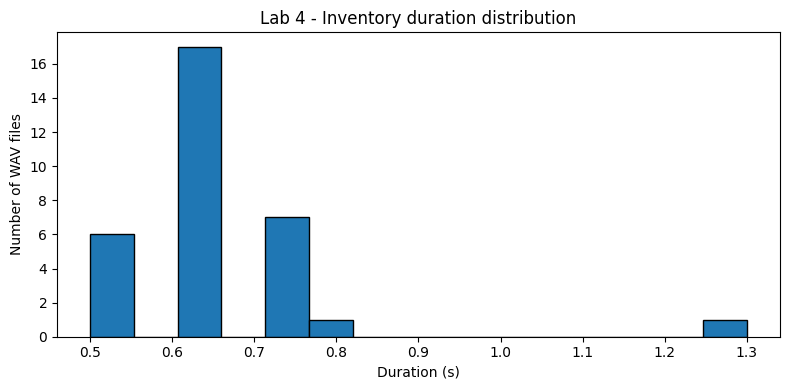

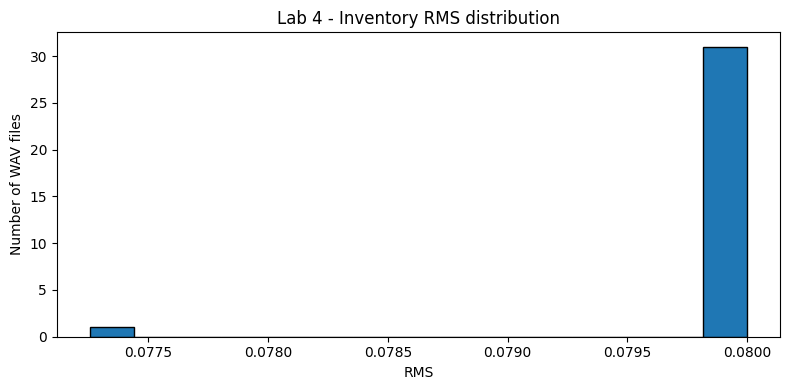

Đã lưu 2 hình trong: c:\xulyamthanh\lab04_2351260688_NguyenNgocTien\figures


In [7]:
if metadata.empty:
    print("Chưa có dữ liệu để vẽ histogram. Các biểu đồ sẽ tạo sau khi có WAV.")
else:
    plt.figure(figsize=(8, 4))
    plt.hist(metadata["duration"], bins=max(5, min(15, len(metadata))), edgecolor="black")
    plt.xlabel("Duration (s)")
    plt.ylabel("Number of WAV files")
    plt.title("Lab 4 - Inventory duration distribution")
    plt.tight_layout()
    plt.savefig(FIG_DIR / "hist_duration.png", dpi=160)
    plt.show()

    plt.figure(figsize=(8, 4))
    plt.hist(metadata["rms"], bins=max(5, min(15, len(metadata))), edgecolor="black")
    plt.xlabel("RMS")
    plt.ylabel("Number of WAV files")
    plt.title("Lab 4 - Inventory RMS distribution")
    plt.tight_layout()
    plt.savefig(FIG_DIR / "hist_rms.png", dpi=160)
    plt.show()
    print("Đã lưu 2 hình trong:", FIG_DIR)


## 6. Tổng kết bước A

**Bước A hoàn tất khi:**
- `normalize_text()` vượt qua các kiểm thử.
- Inventory đủ **16 label**, mỗi label có **2 candidate** (32 WAV).
- Tất cả file xử lý có `16000 Hz`, `1 channel`, `PCM_16`.
- Có `lab4_data/metadata.csv` và hai ảnh histogram.
- Đã nghe thử một số file: tiếng Việt **đúng dấu**, âm tiết không bị cắt, ít tạp âm, không méo tiếng.

**Đầu vào cho bước B** tiếp theo: `lab4_data/units/*.wav` và hàm `normalize_text()`. Bước B sẽ ghép các token thành câu và lưu `raw_concat.wav`.

**Nếu cần kiểm tra kết quả với trợ lý:** gửi `metadata.csv`, `inventory_manifest.csv`, hai ảnh histogram, và vài WAV đại diện (hoặc zip thư mục `units/`).